In [ ]:
!pip -q install openpyxl

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

In [ ]:
uploaded = files.upload()
file_path = list(uploaded.keys())[0]

df = pd.read_excel(file_path, sheet_name="Monthly Population")

df = df.rename(columns={
    "Domestic ( GWh)": "Domestic",
    "Industrial (GWh)": "Industrial",
    "Population (Millions)": "Population",
    "GDP (LKR Million)": "GDP",
    "IIp(index points)": "IIP",
    "Avg Max Temp (Â°C)": "Temp_Max",
    "Avg Min Temp (Â°C)": "Temp_Min",
    "Avg Max RH (%)": "Humidity_Max",
    "Avg Min RH (%)": "Humidity_Min"
})

df["Date"] = pd.to_datetime(df["Date"].astype(str) + "-01")
df = df.sort_values("Date").reset_index(drop=True)

cols = [
    "Domestic", "Industrial", "Population", "GDP", "IIP",
    "Temp_Max", "Temp_Min", "Humidity_Max", "Humidity_Min"
]

for col in cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].interpolate().bfill().ffill()

df.head()

Saving Research_data_set.xlsx to Research_data_set.xlsx


,Date,Population,Temp_Max,Temp_Min,Humidity_Max,Humidity_Min,IIP,GDP,Domestic,Industrial
0,2000-01-01,19.100,30.8,21.8,87,70,122.0,102100,141.666000,146.25
1,2000-02-01,19.118,30.8,22.8,88,69,126.3,100500,142.131000,146.00
2,2000-03-01,19.137,31.8,23.8,89,68,125.8,105800,142.592000,145.75
3,2000-04-01,19.155,31.8,23.8,91,72,122.7,98400,143.062500,145.50
4,2000-05-01,19.173,30.8,24.8,93,76,128.1,100200,141.666667,145.25


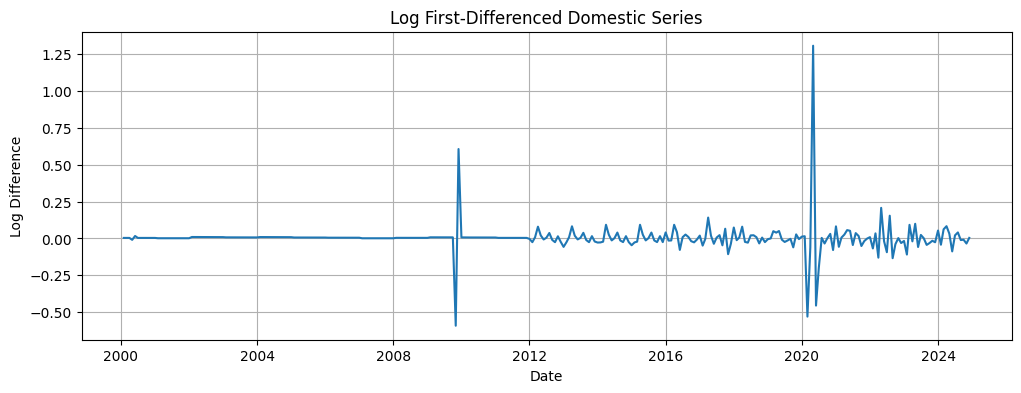

,Date,Domestic,Log_Domestic,Log_Domestic_Diff
0,2000-02-01,142.131000,4.956749,0.003277
1,2000-03-01,142.592000,4.959987,0.003238
2,2000-04-01,143.062500,4.963282,0.003294
3,2000-05-01,141.666667,4.953477,-0.009805
4,2000-06-01,143.993056,4.969765,0.016288


In [ ]:
data = df.copy()

# Log transform
data["Log_Domestic"] = np.log(data["Domestic"])

# First difference after log transformation
data["Log_Domestic_Diff"] = data["Log_Domestic"].diff()

# Remove first NA
data = data.dropna().reset_index(drop=True)

plt.figure(figsize=(12,4))
plt.plot(data["Date"], data["Log_Domestic_Diff"])
plt.title("Log First-Differenced Domestic Series")
plt.xlabel("Date")
plt.ylabel("Log Difference")
plt.grid(True)
plt.show()

data[["Date", "Domestic", "Log_Domestic", "Log_Domestic_Diff"]].head()

In [ ]:
TEST_SIZE = 24

candidate_features = [
    "Population", "GDP", "IIP",
    "Temp_Max", "Temp_Min",
    "Humidity_Max", "Humidity_Min"
]

train_part = data.iloc[:-TEST_SIZE].copy()

X_fs = train_part[candidate_features]
y_fs = train_part["Log_Domestic_Diff"]

# Random Forest importance
rf = RandomForestRegressor(
    n_estimators=500,
    max_depth=4,
    random_state=42
)

rf.fit(X_fs, y_fs)

rf_importance = pd.DataFrame({
    "Feature": candidate_features,
    "RF_Importance": rf.feature_importances_
})

# Mutual Information
mi_scores = mutual_info_regression(X_fs, y_fs, random_state=42)

mi_importance = pd.DataFrame({
    "Feature": candidate_features,
    "MI_Score": mi_scores
})

# Combined ranking
feature_rank = rf_importance.merge(mi_importance, on="Feature")

feature_rank["RF_Rank"] = feature_rank["RF_Importance"].rank(ascending=False)
feature_rank["MI_Rank"] = feature_rank["MI_Score"].rank(ascending=False)

feature_rank["Average_Rank"] = (
    feature_rank["RF_Rank"] + feature_rank["MI_Rank"]
) / 2

feature_rank = feature_rank.sort_values("Average_Rank")

print(feature_rank)

selected_features = feature_rank["Feature"].head(3).tolist()
print("Selected Features:", selected_features)

        Feature  RF_Importance  MI_Score  RF_Rank  MI_Rank  Average_Rank
2           IIP       0.739383  0.193042      1.0      5.0           3.0
0    Population       0.049975  0.364364      3.0      4.0           3.5
1           GDP       0.039987  0.915916      5.0      2.0           3.5
3      Temp_Max       0.039348  0.972735      6.0      1.0           3.5
6  Humidity_Min       0.050869  0.015815      2.0      6.0           4.0
4      Temp_Min       0.032267  0.853773      7.0      3.0           5.0
5  Humidity_Max       0.048171  0.000000      4.0      7.0           5.5
Selected Features: ['IIP', 'Population', 'GDP']


In [ ]:
LOOKBACK = 4

def make_windows(data, target_col, feature_cols, lookback):
    X, y, dates = [], [], []
    use_cols = [target_col] + feature_cols

    for i in range(lookback, len(data)):
        X.append(data[use_cols].iloc[i-lookback:i].values.flatten())
        y.append(data[target_col].iloc[i])
        dates.append(data["Date"].iloc[i])

    return np.array(X), np.array(y), np.array(dates)

X, y, dates = make_windows(
    data=data,
    target_col="Log_Domestic_Diff",
    feature_cols=selected_features,
    lookback=LOOKBACK
)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (295, 16)
y shape: (295,)


In [ ]:
X_temp = X[:-TEST_SIZE]
y_temp = y[:-TEST_SIZE]

X_test = X[-TEST_SIZE:]
y_test = y[-TEST_SIZE:]
dates_test = dates[-TEST_SIZE:]

val_size = int(len(X_temp) * 0.10)

X_train = X_temp[:-val_size]
y_train = y_temp[:-val_size]

X_val = X_temp[-val_size:]
y_val = y_temp[-val_size:]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (244, 16)
Validation: (27, 16)
Test: (24, 16)


In [ ]:
x_pipeline = Pipeline([
    ("scaler", RobustScaler())
])

y_scaler = RobustScaler()

X_train_scaled = x_pipeline.fit_transform(X_train)
X_val_scaled = x_pipeline.transform(X_val)
X_test_scaled = x_pipeline.transform(X_test)

y_train_scaled = y_scaler.fit_transform(y_train.reshape(-1, 1)).flatten()
y_val_scaled = y_scaler.transform(y_val.reshape(-1, 1)).flatten()

print("Robust Scaling Done")

Robust Scaling Done


In [8]:

# HYPERPARAMETER TUNING TEST
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2
import pandas as pd
import numpy as np
import tensorflow as tf
import random

SEED = 42

param_grid = [
    {
        "units1": 8,
        "units2": 4,
        "lr": 0.0002,
        "batch_size": 16,
        "l2_value": 0.001,
        "dropout": 0.0
    },
    {
        "units1": 16,
        "units2": 8,
        "lr": 0.0002,
        "batch_size": 16,
        "l2_value": 0.001,
        "dropout": 0.0
    },
    {
        "units1": 16,
        "units2": 8,
        "lr": 0.0001,
        "batch_size": 16,
        "l2_value": 0.001,
        "dropout": 0.1
    },
    {
        "units1": 8,
        "units2": 4,
        "lr": 0.0001,
        "batch_size": 8,
        "l2_value": 0.001,
        "dropout": 0.1
    }
]

def build_tuned_arnet(input_dim, units1, units2, lr, l2_value, dropout):
    model = Sequential()
    model.add(Input(shape=(input_dim,)))
    model.add(Dense(units1, activation="relu", kernel_regularizer=l2(l2_value)))

    if dropout > 0:
        model.add(Dropout(dropout))

    model.add(Dense(units2, activation="relu"))
    model.add(Dense(1))

    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss="mse",
        metrics=["mae"]
    )

    return model


tuning_results = []

for i, params in enumerate(param_grid, start=1):
    print(f"\nRunning tuning test {i}/{len(param_grid)}")
    print(params)

    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    model_temp = build_tuned_arnet(
        input_dim=X_train_scaled.shape[1],
        units1=params["units1"],
        units2=params["units2"],
        lr=params["lr"],
        l2_value=params["l2_value"],
        dropout=params["dropout"]
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True
    )

    history_temp = model_temp.fit(
        X_train_scaled,
        y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=200,
        batch_size=params["batch_size"],
        callbacks=[early_stop],
        shuffle=False,
        verbose=0
    )

    best_val_loss = min(history_temp.history["val_loss"])
    best_epoch = np.argmin(history_temp.history["val_loss"]) + 1

    tuning_results.append({
        "Test": i,
        "Units_1": params["units1"],
        "Units_2": params["units2"],
        "Learning_Rate": params["lr"],
        "Batch_Size": params["batch_size"],
        "L2": params["l2_value"],
        "Dropout": params["dropout"],
        "Best_Val_Loss": best_val_loss,
        "Best_Epoch": best_epoch
    })

tuning_results_df = pd.DataFrame(tuning_results)
tuning_results_df = tuning_results_df.sort_values("Best_Val_Loss")

print("\nHyperparameter Tuning Results:")
print(tuning_results_df)

best_params = tuning_results_df.iloc[0]
print("\nBest Hyperparameters:")
print(best_params)


Running tuning test 1/4
{'units1': 8, 'units2': 4, 'lr': 0.0002, 'batch_size': 16, 'l2_value': 0.001, 'dropout': 0.0}

Running tuning test 2/4
{'units1': 16, 'units2': 8, 'lr': 0.0002, 'batch_size': 16, 'l2_value': 0.001, 'dropout': 0.0}

Running tuning test 3/4
{'units1': 16, 'units2': 8, 'lr': 0.0001, 'batch_size': 16, 'l2_value': 0.001, 'dropout': 0.1}

Running tuning test 4/4
{'units1': 8, 'units2': 4, 'lr': 0.0001, 'batch_size': 8, 'l2_value': 0.001, 'dropout': 0.1}

Hyperparameter Tuning Results:
   Test  Units_1  Units_2  Learning_Rate  Batch_Size     L2  Dropout  \
3     4        8        4         0.0001           8  0.001      0.1   
2     3       16        8         0.0001          16  0.001      0.1   
1     2       16        8         0.0002          16  0.001      0.0   
0     1        8        4         0.0002          16  0.001      0.0   

   Best_Val_Loss  Best_Epoch  
3       0.299301         200  
2       0.740540         200  
1       1.022197         200  
0     

In [ ]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2

# BUILD MODEL
def build_arnet(input_dim):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(8, activation="relu", kernel_regularizer=l2(0.001)),
        Dense(4, activation="relu", kernel_regularizer=l2(0.001)),
        Dense(1)
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.0001),
        loss="mse",
        metrics=["mae"]
    )

    return model

# Create model
model = build_arnet(X_train_scaled.shape[1])
model.summary()

#  CALLBACKS
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)
lr_scheduler = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=8,
    min_lr=1e-6,
    verbose=1
)

# 4. TRAIN MODEL
history = model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=120,
    batch_size=6,
    callbacks=[early_stop,lr_scheduler],
    verbose=1
)

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_42 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 177 (708.00 B)

 Trainable params: 177 (708.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/120
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 2.1376 - mae: 0.3315 - val_loss: 2.2357 - val_mae: 0.7628 - learning_rate: 1.0000e-04
Epoch 2/120
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.0284 - mae: 0.3217 - val_loss: 2.1291 - val_mae: 0.7498 - learning_rate: 1.0000e-04
Epoch 3/120
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.9242 - mae: 0.3128 - val_loss: 2.0281 - val_mae: 0.7369 - learning_rate: 1.0000e-04
Epoch 4/120
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.8253 - mae: 0.3043 - val_loss: 1.9326 - val_mae: 0.7241 - learning_rate: 1.0000e-04
Epoch 5/120
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.7317 - mae: 0.2960 - val_loss: 1.8425 - val_mae: 0.7118 - learning_rate: 1.0000e-04
Epoch 6/120
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.6435 - mae: 0.2884 - val_loss: 1.7580 - val_mae: 0.7002 - learning_rate: 1.0000e-04
Epoch 7/120
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.5603 - mae: 0.2812 - val_loss: 1.6783 - val_mae: 0.6891 - learning_ra

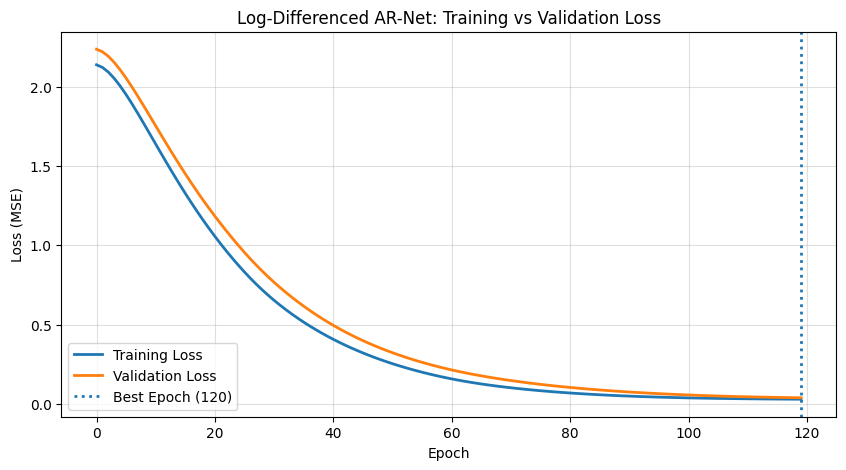

In [ ]:
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

best_epoch = np.argmin(val_loss) + 1

plt.figure(figsize=(10, 5))

plt.plot(
    train_loss,
    label="Training Loss",
    linewidth=2
)

plt.plot(
    val_loss,
    label="Validation Loss",
    linewidth=2
)

plt.axvline(
    best_epoch - 1,
    linestyle=":",
    linewidth=2,
    label=f"Best Epoch ({best_epoch})"
)

plt.title("Log-Differenced AR-Net: Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()


In [ ]:
pred_scaled = model.predict(X_test_scaled, verbose=0)

# Inverse scale predicted log differences
pred_log_diff = y_scaler.inverse_transform(pred_scaled).flatten()

original_df = df.set_index("Date")

actual_original = []
pred_original = []

for d, pred_ldiff in zip(dates_test, pred_log_diff):
    d = pd.to_datetime(d)
    prev_month = d - pd.DateOffset(months=1)

    prev_actual = original_df.loc[prev_month, "Domestic"]
    actual_now = original_df.loc[d, "Domestic"]

    # correct inverse from log-difference
    pred_now = prev_actual * np.exp(pred_ldiff)

    actual_original.append(actual_now)
    pred_original.append(pred_now)

actual_original = np.array(actual_original)
pred_original = np.array(pred_original)


In [ ]:
rmse = np.sqrt(mean_squared_error(actual_original, pred_original))
mae = mean_absolute_error(actual_original, pred_original)
mape = np.mean(np.abs((actual_original - pred_original) / actual_original)) * 100

smape = np.mean(
    2 * np.abs(pred_original - actual_original) /
    (np.abs(actual_original) + np.abs(pred_original))
) * 100

print("FINAL TEST RESULTS")
print("-------------------")
print("RMSE :", rmse)
print("MAE  :", mae)
print("MAPE :", mape, "%")
print("sMAPE:", smape, "%")

FINAL TEST RESULTS
-------------------
RMSE : 20.137444191784567
MAE  : 16.483876691098015
MAPE : 4.342290296644149 %
sMAPE: 4.324665021292029 %


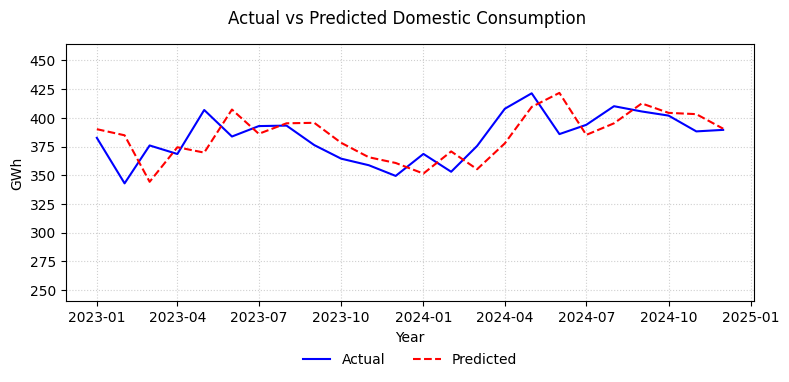

In [64]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8, 4))

plt.plot(dates_test, actual_original, color='blue', label='Actual', linewidth=1.5)
plt.plot(dates_test, pred_original, color='red', label='Predicted', linestyle='--', linewidth=1.5)


plt.title(f"Actual vs Predicted Domestic Consumption ", fontsize=12, pad=15)


plt.xlabel("Year", fontsize=10)
plt.ylabel("GWh", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)


current_min = min(min(actual_original), min(pred_original))
current_max = max(max(actual_original), max(pred_original))
plt.ylim(current_min * 0.7, current_max * 1.1)


plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)

plt.tight_layout()
plt.show()

In [ ]:
n_forecast = 3
forecast_scaled = []

current_input = X_test_scaled[-1].reshape(1, -1)

for _ in range(n_forecast):
    pred = model.predict(current_input, verbose=0)
    forecast_scaled.append(pred[0][0])

    current_input = np.roll(current_input, -1)
    current_input[0, -1] = pred

/tmp/ipykernel_10611/3759885938.py:11: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  current_input[0, -1] = pred


In [ ]:
last_log = np.log(df["Domestic"].iloc[-1])

forecast_log = []

for val in forecast_scaled:
    new_log = last_log + val
    forecast_log.append(new_log)
    last_log = new_log

forecast_values = np.exp(forecast_log)

In [ ]:
future_dates = pd.date_range(
    start="2025-01-01",
    periods=3,
    freq="MS"
)

In [ ]:
forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Forecast_Domestic_GWh": forecast_values
})

forecast_df

,Date,Forecast_Domestic_GWh
0,2025-01-01,392.205463
1,2025-02-01,460.603364
2,2025-03-01,428.356611
